# 03 - Interpretability — Grad-CAM & LIME

A model that reaches high accuracy is not automatically trustworthy: it
might be keying on **artefacts** (e.g. hair, dark dermatoscope
vignette) rather than the lesion. Here we open the black box two ways:
**Grad-CAM** (where does the model look) and **LIME** (which superpixels
support the prediction). Then we use both, on the model's actual failures,
to ask whether its mistakes come from genuinely hard lesions or from
dataset artefacts.

(Also tried SHAP's `GradientExplainer`; its pixel-level attributions
were too noisy on these images to read reliably, so it's dropped here in
favour of the two methods that gave a legible signal.)

**Prerequisite.** A trained checkpoint.

In [14]:
import sys, os
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
os.chdir(ROOT)

import yaml
CFG = yaml.safe_load(Path("config.yaml").read_text())
IMAGES_DIR = Path(CFG["data"]["raw_dir"]) / "images"
SPLITS_CSV = CFG["data"]["splits_csv"]
print("project root:", ROOT)


project root: /home/aproia/AML-HAM10000


The best model is picked following malignant-missed-as-benign criterion, measured on the validation set. Let's assume to have a screening task, so the model that most rarely calls a malignant/premalignant lesion (mel, bcc, akiec) "benign" is the one that matters, and that is resnet_weighted.

In [15]:
import numpy as np, torch, matplotlib.pyplot as plt
from torch.utils.data import DataLoader
from src.dataset import HAM10000Dataset, CLASSES, CLASS_FULLNAME, IDX_TO_CLASS
from src.transforms import build_transforms, normalization_for_model
from src.models import build_model, gradcam_target_layer
from src.evaluate import load_checkpoint

device = "cuda" if torch.cuda.is_available() else "cpu"

RUN_NAME  = "resnet_weighted"
MODEL_NAME = "resnet18"         # must match the run
CKPT = Path(CFG["paths"]["models_dir"]) / f"{RUN_NAME}.pt"

# Must match the normalization used at training time for this model family
# (dataset stats for simple_cnn, ImageNet stats for pretrained backbones).
MEAN, STD = normalization_for_model(
    MODEL_NAME, CFG["data"]["normalization"]["mean"], CFG["data"]["normalization"]["std"]
)
_, eval_tf = build_transforms(CFG["data"]["image_size"], MEAN, STD)
model = build_model(MODEL_NAME, pretrained=False)
load_checkpoint(model, CKPT, device=device); model.to(device).eval()
target_layer = gradcam_target_layer(model, MODEL_NAME)
print("explaining:", RUN_NAME)

explaining: resnet_weighted


In [16]:
# Grab one test image per class to explain
test_ds = HAM10000Dataset(SPLITS_CSV, IMAGES_DIR, "test", eval_tf)
labels = test_ds.labels
examples = {}
for cls_idx in range(len(CLASSES)):
    idx = int(np.where(labels == cls_idx)[0][0])
    x, y = test_ds[idx]
    examples[CLASSES[cls_idx]] = (x, y)
print("collected one example per class")

collected one example per class


## 1. Grad-CAM — where is the model looking?

For each class we overlay the heatmap and print the model's prediction. A
healthy sign is heat concentrated on the lesion, not on the corners or
on hair.

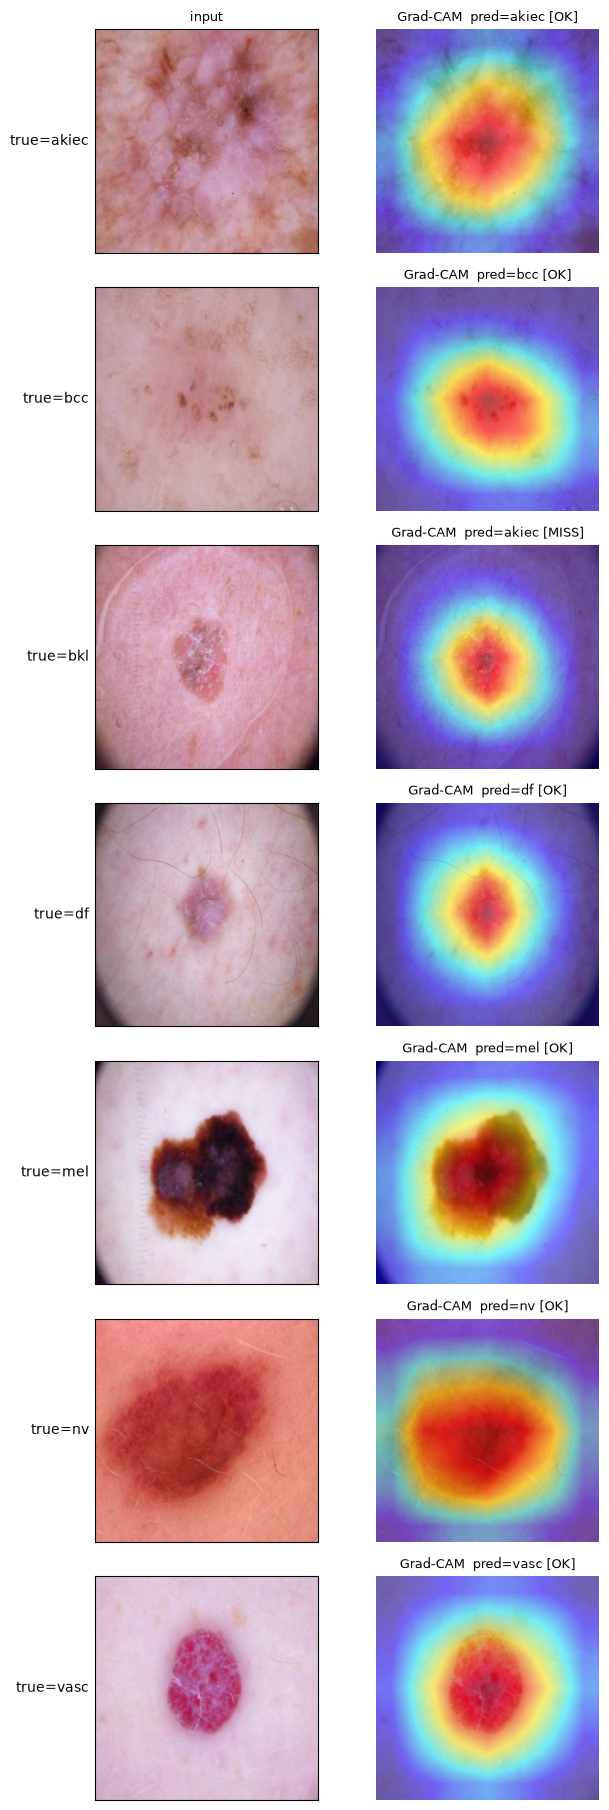

In [17]:
from src.interpret import gradcam_heatmap, overlay_heatmap

fig, axes = plt.subplots(len(CLASSES), 2, figsize=(7, 2.6 * len(CLASSES)))
for r, (cls, (x, y)) in enumerate(examples.items()):
    with torch.no_grad():
        pred = int(model(x.unsqueeze(0).to(device)).argmax(1))
    heat = gradcam_heatmap(model, target_layer, x, target_class=pred, device=device)
    over = overlay_heatmap(x, heat, MEAN, STD)
    from src.transforms import denormalize
    axes[r, 0].imshow(denormalize(x, MEAN, STD).permute(1, 2, 0).cpu().numpy())
    axes[r, 0].set_ylabel(f"true={cls}", rotation=0, ha="right", va="center")
    axes[r, 0].set_xticks([]); axes[r, 0].set_yticks([])
    axes[r, 1].imshow(over)
    ok = "OK" if IDX_TO_CLASS[pred] == cls else "MISS"
    axes[r, 1].set_title(f"Grad-CAM  pred={IDX_TO_CLASS[pred]} [{ok}]", fontsize=9)
    axes[r, 1].axis("off")
axes[0, 0].set_title("input", fontsize=9)
plt.tight_layout(); plt.savefig("figures/gradcam_per_class.png", dpi=120); plt.show()

## 2. LIME — superpixel explanation

LIME perturbs contiguous superpixels and learns which ones the prediction
depends on. We show the top regions supporting the predicted class for a
melanoma example.

  0%|          | 0/800 [00:00<?, ?it/s]

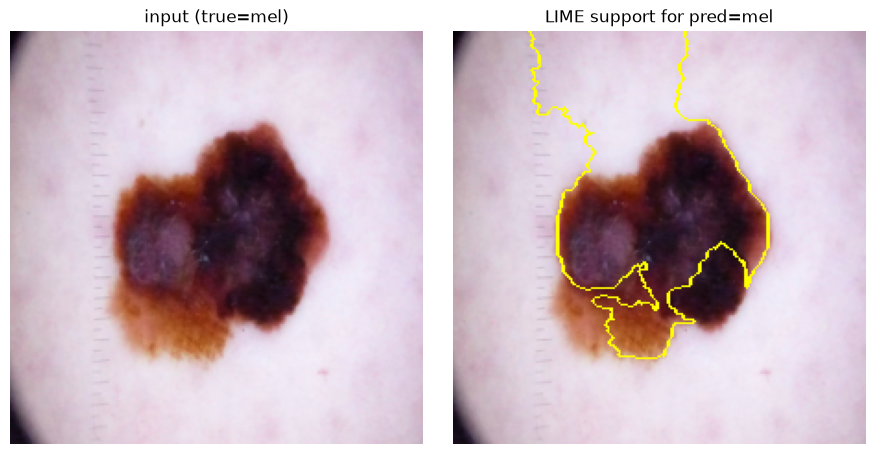

In [18]:
from src.interpret import lime_explain
from skimage.segmentation import mark_boundaries

cls = "mel"
x, _ = examples[cls]
explanation, rgb = lime_explain(model, x, eval_tf, device=device,
                                top_labels=3, num_samples=800, mean=MEAN, std=STD)
label = explanation.top_labels[0]
temp, mask = explanation.get_image_and_mask(
    label, positive_only=True, num_features=6, hide_rest=False)

fig, ax = plt.subplots(1, 2, figsize=(9, 4.5))
ax[0].imshow(rgb); ax[0].set_title(f"input (true={cls})"); ax[0].axis("off")
ax[1].imshow(mark_boundaries(temp / 255.0, mask))
ax[1].set_title(f"LIME support for pred={IDX_TO_CLASS[label]}"); ax[1].axis("off")
plt.tight_layout(); plt.savefig("figures/lime_mel.png", dpi=120); plt.show()

## 3. Failure analysis: melanomas the model called benign

The examples above are just the first test image of each class, so they say
little about the failures that matter. Under the selection criterion defined previously, the
cases worth explaining are (for example) the **true melanomas predicted as bkl / df / nv /
vasc**. For the most confidently missed ones we run Grad-CAM and LIME and
ask: was the model looking at the lesion and misjudging it, or looking
somewhere it shouldn't (rulers, hair, vignette, background)? The first case
is a modelling limit; the second is a dataset artefact we could try to fix.

melanomas in test set: 165, called benign: 46


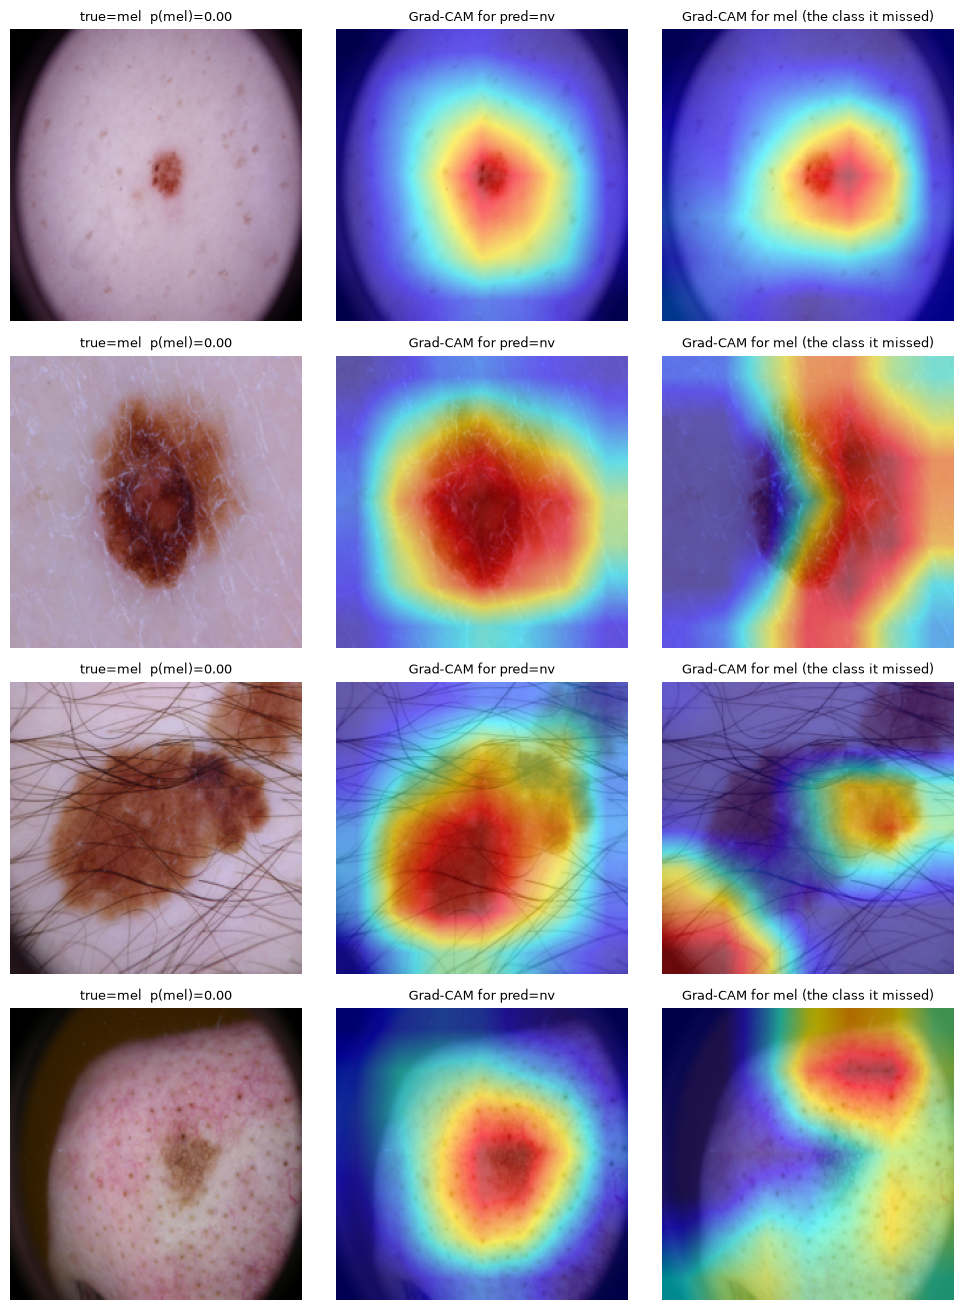

In [19]:
from src.evaluate import predict

BENIGN = ["bkl", "df", "nv", "vasc"]
benign_idx = [CLASSES.index(c) for c in BENIGN]
mel_idx = CLASSES.index("mel")

test_loader = DataLoader(test_ds, batch_size=128, num_workers=8, pin_memory=True)
y_true, y_pred, y_prob = predict(model, test_loader, device)
fn_idx = np.where((y_true == mel_idx) & np.isin(y_pred, benign_idx))[0]
print(f"melanomas in test set: {(y_true == mel_idx).sum()}, called benign: {len(fn_idx)}")

# show the most confidently missed first
order = np.argsort(-y_prob[fn_idx].max(axis=1))
fn_show = fn_idx[order][:4]

fig, axes = plt.subplots(len(fn_show), 3, figsize=(10, 3.3 * len(fn_show)))
for r, i in enumerate(fn_show):
    x, _ = test_ds[int(i)]
    pred = int(y_pred[i])
    axes[r, 0].imshow(denormalize(x, MEAN, STD).permute(1, 2, 0).numpy())
    axes[r, 0].set_title(f"true=mel  p(mel)={y_prob[i, mel_idx]:.2f}", fontsize=9)
    for c, (target, name) in enumerate([(pred, f"pred={IDX_TO_CLASS[pred]}"), (mel_idx, "mel (the class it missed)")], start=1):
        heat = gradcam_heatmap(model, target_layer, x, target_class=target, device=device)
        axes[r, c].imshow(overlay_heatmap(x, heat, MEAN, STD))
        axes[r, c].set_title(f"Grad-CAM for {name}", fontsize=9)
    for c in range(3):
        axes[r, c].axis("off")
plt.tight_layout(); plt.savefig("figures/gradcam_mel_false_negatives.png", dpi=120); plt.show()

  0%|          | 0/800 [00:00<?, ?it/s]

  0%|          | 0/800 [00:00<?, ?it/s]

  0%|          | 0/800 [00:00<?, ?it/s]

  0%|          | 0/800 [00:00<?, ?it/s]

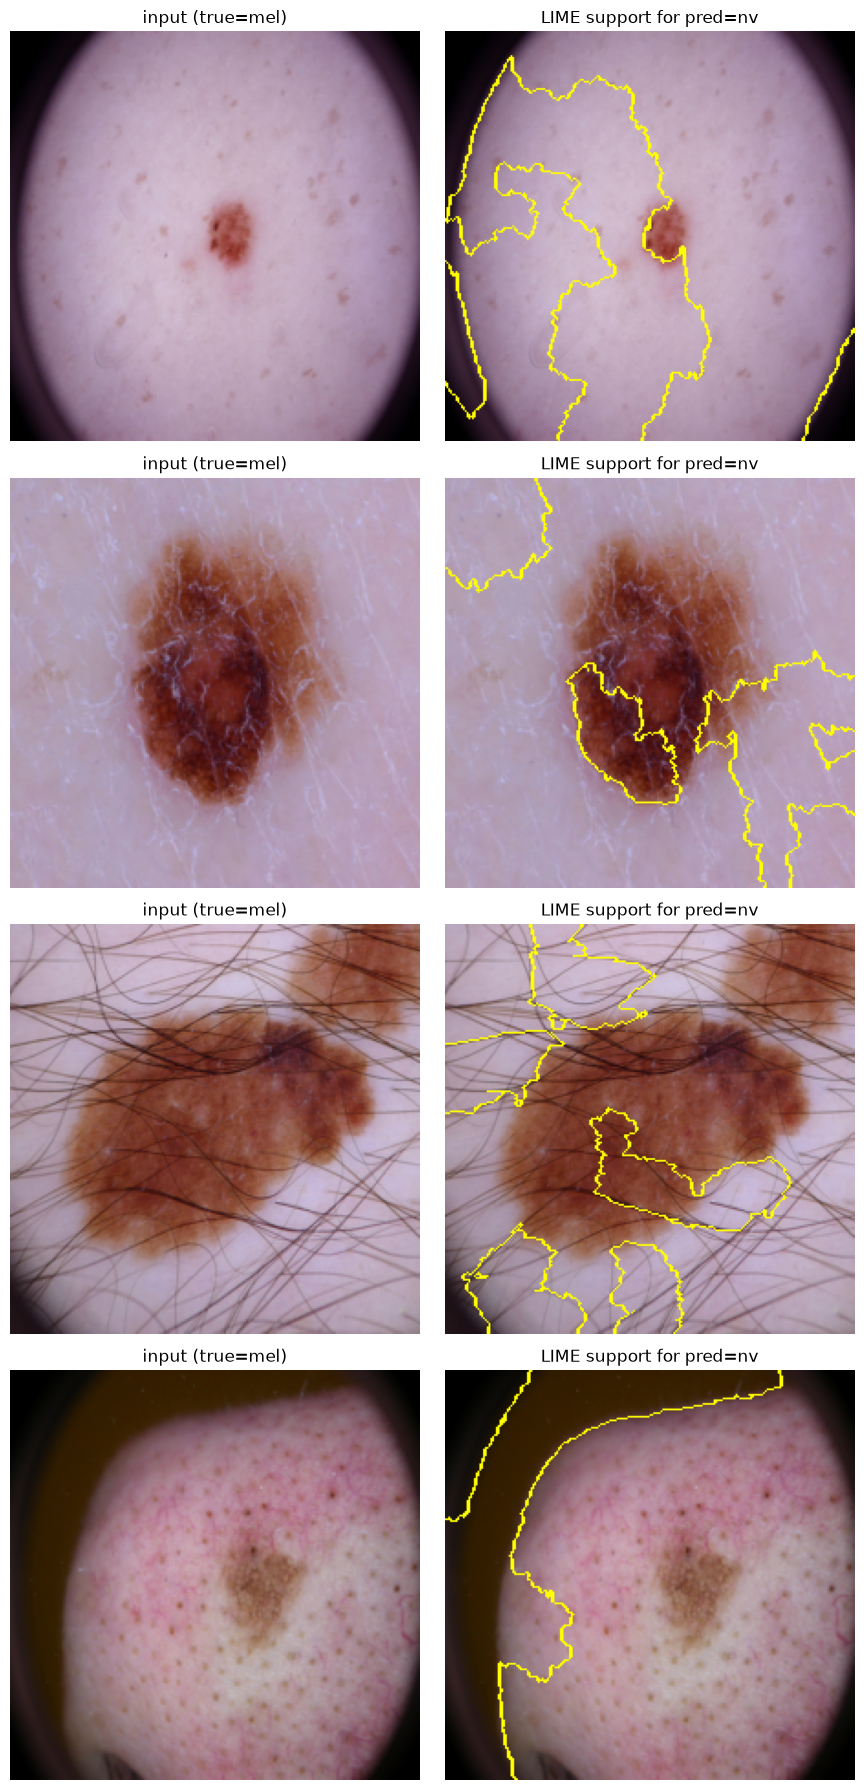

In [20]:
from src.interpret import lime_explain
from skimage.segmentation import mark_boundaries

fig, axes = plt.subplots(len(fn_show), 2, figsize=(9, 4.5 * len(fn_show)))
axes = np.atleast_2d(axes)
for r, i in enumerate(fn_show):
    x, _ = test_ds[int(i)]
    explanation, rgb = lime_explain(model, x, eval_tf, device=device,
                                    top_labels=3, num_samples=800, mean=MEAN, std=STD)
    label = explanation.top_labels[0]
    temp, mask = explanation.get_image_and_mask(
        label, positive_only=True, num_features=6, hide_rest=False)
    axes[r, 0].imshow(rgb); axes[r, 0].set_title("input (true=mel)"); axes[r, 0].axis("off")
    axes[r, 1].imshow(mark_boundaries(temp / 255.0, mask))
    axes[r, 1].set_title(f"LIME support for pred={IDX_TO_CLASS[label]}"); axes[r, 1].axis("off")
plt.tight_layout(); plt.savefig("figures/lime_mel_false_negatives.png", dpi=120); plt.show()

### Discussion: are these misses genuinely hard, or is the model looking at the wrong thing?

Reading Grad-CAM and LIME together across the four most confidently missed
melanomas (all predicted `nv` with `p(mel) ≈ 0.00`), the failures do not
share a single cause:

- **Case 1** (clean, well-centered lesion): Grad-CAM for `pred=nv` and for
  the missed `mel` target both concentrate tightly on the lesion, with
  near-identical footprints, so by Grad-CAM the model is looking at the right
  place and still gets it wrong. LIME is less clear: its `nv` outlines cover
  mostly the surrounding skin and small parts of the dark border, with only
  part of the lesion enclosed. This is most likely a modelling limit rather
  than something preprocessing would fix, but the two methods do not fully agree.
- **Case 2**: Grad-CAM for `nv` is centred on the lesion, but the `mel`-target
  map lies mostly on skin to the right of it. LIME's `nv` outlines cover one
  part of the lesion plus several patches of surrounding skin. No specific
  artefact (dense hair, dark corner) is visible, so this case is ambiguous:
  the model may be using skin context, and we cannot tell that apart from a
  genuinely hard lesion here.
- **Case 3** (dense hair): Grad-CAM's heat for the `mel` target splits off
  the lesion into the corner of the image, and LIME's support region for `nv`
  includes a chunk of hair-covered skin outside the lesion boundary. The hair
  is plausibly contributing to the wrong call.
- **Case 4** (dark dermatoscope vignette): Grad-CAM for `nv` is centred on the
  lesion, but for the missed `mel` target the heat moves off the lesion to the
  top of the image, close to the dark border. LIME's support region for `nv`
  lies entirely in the dark corner, none of it on the lesion. Same pattern: a
  non-lesion artefact plausibly contributing to the miss.

Two of the four misses (cases 3 and 4) show attention plausibly drawn to hair
or vignette artefacts rather than the lesion; case 1 looks like a genuinely
hard lesion, and case 2 is ambiguous. So at least part of the 24.8%
malignant-missed-as-benign rate is not simply "the task is hard": some of it
may be addressable with hair/artefact-removal preprocessing rather than a
larger or better model. This is a hypothesis, not tested here.